# Notebook 08 - Kontext-Indikatoren: Post-hoc-Korrelationsanalyse

**Ansatz:** Statt die Kontext-Indikatoren (K01-K19) als Zeitreihen-Feature
in das Modelltraining zu integrieren (was wegen instabiler Spalten-
reihenfolge und -verfuegbarkeit ueber die Jahre sehr aufwendig waere),
werden sie hier POST-HOC mit den bereits vorliegenden Modellergebnissen
verknuepft:

- SHAP-Wichtigkeit je Planungsraum (Notebook 06)
- Prognostizierte Statusveraenderung 2025->2027 (Notebook 07)

Genutzt wird NUR EIN Jahrgang (2023, passend zum Testzeitraum) - keine
Multi-Jahres-Interpolation noetig.

**Voraussetzung:** Notebook 06 und 07 muessen vorher gelaufen sein
(liefern results/shap_pro_plr.csv und results/prognose_2027.csv).

In [1]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 1: Imports & vorhandene Ergebnisse laden
# ═══════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import os
import re
import warnings
warnings.filterwarnings('ignore')

from scipy.stats import pearsonr, spearmanr

shap_pro_plr = pd.read_csv('../results/shap_pro_plr.csv')
shap_pro_plr['plr_id'] = shap_pro_plr['plr_id'].astype(str).str.zfill(8)

prognose = pd.read_csv('../results/prognose_2027.csv')
prognose['plr_id'] = prognose['plr_id'].astype(str).str.zfill(8)

print(f'✅ SHAP pro PLR geladen: {shap_pro_plr.shape}')
print(f'   Spalten: {shap_pro_plr.columns.tolist()}')
print(f'\n✅ Prognose 2027 geladen: {prognose.shape}')
print(f'   Spalten: {prognose.columns.tolist()}')

✅ SHAP pro PLR geladen: (542, 8)
   Spalten: ['plr_id', 'shap_arbeitslosigkeit', 'shap_sgb2_quote', 'shap_kinderarmut', 'shap_dist_zentrum', 'shap_status_lag', 'shap_staerke', 'dominant_feature']

✅ Prognose 2027 geladen: (539, 6)
   Spalten: ['plr_id', 'status_2025_bekannt', 'status_2027_lstm', 'veraenderung_lstm', 'status_2027_tft', 'veraenderung_tft']


In [2]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 2: Robuster Kontext-Indikator-Loader (namensbasiert!)
# ═══════════════════════════════════════════════════════════════
# WICHTIG: Die Spaltenreihenfolge der Kontext-Indikator-Tabellen ist
# zwischen den MSS-Berichtsjahren NICHT stabil (anders als bei den
# Index-Indikatoren S1/S3/S4!). Dieser Loader sucht daher automatisch
# die Kopfzeile und identifiziert Spalten ueber ihren NAMEN
# ('K 09', 'K09', 'K9' etc. werden alle als 'K09' erkannt), nicht
# ueber ihre Position.

K_BESCHREIBUNGEN = {
    'K01': 'Jugendarbeitslosigkeit',
    'K02': 'Alleinerziehende Haushalte',
    'K03': 'Altersarmut gesamt',
    'K04': 'Kinder/Jugendliche mit Migrationshintergrund',
    'K05': 'Einwohner mit Migrationshintergrund',
    'K06': 'Veraenderung Auslaenderanteil',
    'K07': 'Auslaendische Transferbezieher',
    'K08': 'Staedtische Wohnungen',
    'K09': 'Einfache Wohnlage (inkl. Laermbelastung)',
    'K10': 'Wohndauer ueber 5 Jahre',
    'K11': 'Wanderungsvolumen',
    'K12': 'Wanderungssaldo',
    'K13': 'Wanderungssaldo Kinder unter 6 Jahren',
    'K14': 'Wohnraeume',
    'K15': 'Wohnflaeche',
    'K16': 'Auslaenderinnen und Auslaender',
    'K17': 'Nicht-EU-Auslaender',
    'K18': 'Altersarmut weiblich',
    'K19': 'Altersarmut maennlich',
}


def normalisiere_k_code(text):
    """Erkennt 'K 09', 'K09', 'K9' etc. und normalisiert zu 'K09'."""
    match = re.match(r'^K\s?(\d{1,2})$', str(text).strip())
    if match:
        return f'K{int(match.group(1)):02d}'
    return None


def load_kontext_indikatoren(path, max_scan_rows=20):
    """Laedt eine MSS-Kontext-Indikatoren-Excel-Datei robust: sucht die
    Kopfzeile automatisch (statt fixer Zeilennummer) und identifiziert
    K-Spalten ueber ihren Namen.
    """
    xl = pd.ExcelFile(path)
    data_sheets = [s for s in xl.sheet_names
                   if 'Erläuterungen' not in s and 'Erlaeuterungen' not in s]
    sheet_name = data_sheets[0] if data_sheets else xl.sheet_names[0]

    raw = pd.read_excel(xl, sheet_name=sheet_name, header=None, nrows=max_scan_rows)

    header_row = None
    for i in range(len(raw)):
        row_vals = raw.iloc[i].tolist()
        k_treffer = sum(1 for v in row_vals if normalisiere_k_code(v) is not None)
        if k_treffer >= 3:  # Kopfzeile hat mehrere K-Spalten nebeneinander
            header_row = i
            break

    if header_row is None:
        raise RuntimeError(
            f'Keine Kopfzeile mit K-Indikatoren in {path} gefunden! '
            f'Bitte Datei manuell pruefen.'
        )

    print(f'   Kopfzeile gefunden in Zeile {header_row}')

    df = pd.read_excel(xl, sheet_name=sheet_name, header=header_row)
    cols = list(df.columns)

    rename_map = {}
    for c in cols:
        k_code = normalisiere_k_code(c)
        if k_code:
            rename_map[c] = k_code
    df = df.rename(columns=rename_map)

    # PLR-ID Spalte identifizieren: erste Spalte mit 6-8-stelligen Zahlen
    plr_col = None
    for c in df.columns:
        sample = df[c].dropna().astype(str).str.strip()
        if sample.str.match(r'^\d{6,8}$').mean() > 0.5:
            plr_col = c
            break
    if plr_col is None:
        raise RuntimeError('Keine PLR-ID-Spalte gefunden!')

    df = df.rename(columns={plr_col: 'plr_id'})
    df['plr_id'] = df['plr_id'].astype(str).str.strip()
    df = df[df['plr_id'].str.match(r'^\d{6,8}$')]
    df['plr_id'] = df['plr_id'].str.zfill(8)

    k_spalten_gefunden = [c for c in df.columns if c in K_BESCHREIBUNGEN]
    print(f'   Gefundene K-Indikatoren ({len(k_spalten_gefunden)}): {sorted(k_spalten_gefunden)}')

    return df[['plr_id'] + k_spalten_gefunden].reset_index(drop=True)


print('✅ Loader-Funktion definiert!')

✅ Loader-Funktion definiert!


In [3]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 3: Kontext-Indikatoren fuer 2023 laden
# ═══════════════════════════════════════════════════════════════
# Nur EIN Jahrgang noetig (2023, passend zum Testzeitraum) - keine
# Interpolation ueber mehrere Jahre erforderlich.

KONTEXT_PATH_2023 = '../data/raw/mss_kontext_2023.xlsx'  # ⚠️ Pfad anpassen!

if not os.path.exists(KONTEXT_PATH_2023):
    raise FileNotFoundError(
        f'{KONTEXT_PATH_2023} nicht gefunden! '
        'Bitte die Kontext-Indikatoren-Excel-Datei fuer 2023 dort ablegen '
        '(Download: berlin.de MSS-Bericht 2023, Tabellen der Kontext-Indikatoren).'
    )

print('🔄 Lade Kontext-Indikatoren 2023...')
df_kontext = load_kontext_indikatoren(KONTEXT_PATH_2023)
print(f'\n✅ {len(df_kontext)} PLR mit Kontext-Indikatoren geladen')
print(df_kontext.head())

🔄 Lade Kontext-Indikatoren 2023...
   Kopfzeile gefunden in Zeile 17
   Gefundene K-Indikatoren (19): ['K01', 'K02', 'K03', 'K04', 'K05', 'K06', 'K07', 'K08', 'K09', 'K10', 'K11', 'K12', 'K13', 'K14', 'K15', 'K16', 'K17', 'K18', 'K19']

✅ 542 PLR mit Kontext-Indikatoren geladen
     plr_id       K01        K02        K03        K18        K19        K04  \
0  01100101  2.247191  26.609442  10.787172  13.114754   8.125000  85.714286   
1  01100102  0.000000  26.111111   6.910569   0.000000   0.000000  88.104089   
2  01100103  2.823920  28.045977  19.832109  21.374046  17.948718  82.394366   
3  01100104  3.318250  25.225225  30.327869  30.219780  30.434783  80.100756   
4  01100205  0.000000  19.396552   6.561086   0.000000   0.000000  88.859416   

         K05        K16       K06        K17        K07  K08  K14  K15  \
0  64.083123  43.302443  2.735026  70.752270   9.447166  NaN  NaN  NaN   
1  70.829171  54.445554  3.691786  75.045872   4.003906  NaN  NaN  NaN   
2  61.321088  38.6

In [4]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 4: Mit SHAP-Ergebnissen und Prognose verknuepfen
# ═══════════════════════════════════════════════════════════════

df_analyse = df_kontext.merge(shap_pro_plr, on='plr_id', how='inner')
df_analyse = df_analyse.merge(prognose, on='plr_id', how='inner')

print(f'✅ Gemeinsamer Datensatz: {len(df_analyse)} PLR '
      f'(Kontext ∩ SHAP ∩ Prognose)')

if len(df_analyse) < 30:
    print('⚠️ Sehr wenige gemeinsame PLR - pruefen ob plr_id-Formate '
          'zwischen den Quellen uebereinstimmen!')

k_spalten = [c for c in df_analyse.columns if re.match(r'^K\d{2}$', c)]
shap_spalten = [c for c in df_analyse.columns if c.startswith('shap_')]

print(f'\nK-Indikatoren im Datensatz: {k_spalten}')
print(f'SHAP-Spalten im Datensatz: {shap_spalten}')

✅ Gemeinsamer Datensatz: 539 PLR (Kontext ∩ SHAP ∩ Prognose)

K-Indikatoren im Datensatz: ['K01', 'K02', 'K03', 'K18', 'K19', 'K04', 'K05', 'K16', 'K06', 'K17', 'K07', 'K08', 'K14', 'K15', 'K09', 'K10', 'K11', 'K12', 'K13']
SHAP-Spalten im Datensatz: ['shap_arbeitslosigkeit', 'shap_sgb2_quote', 'shap_kinderarmut', 'shap_dist_zentrum', 'shap_status_lag', 'shap_staerke']


In [5]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 5: Korrelationsanalyse - Kontext-Indikatoren vs. Ergebnisse
# ═══════════════════════════════════════════════════════════════
# Sowohl Pearson (lineare Korrelation) als auch Spearman (Rangkorrelation)
# werden berechnet, da raeumliche Sozialdaten haeufig nicht normalverteilt
# sind und Spearman gegenueber Ausreissern/Nicht-Normalverteilung robuster
# ist. Bei stark abweichenden Werten ist Spearman als robusteres Mass zu
# bevorzugen (vgl. Methodikkapitel).

ziel_variablen = {
    'shap_staerke': 'Staerke des dominanten SHAP-Einflusses',
    'veraenderung_tft': 'Prognostizierte Statusveraenderung 2025->2027 (TFT)',
}
ziel_variablen = {k: v for k, v in ziel_variablen.items() if k in df_analyse.columns}

korrelations_ergebnisse = []

for k_col in k_spalten:
    for ziel_col, ziel_label in ziel_variablen.items():
        gueltige = df_analyse[[k_col, ziel_col]].dropna()
        if len(gueltige) < 10:
            continue
        r_pearson, p_pearson = pearsonr(gueltige[k_col], gueltige[ziel_col])
        r_spearman, p_spearman = spearmanr(gueltige[k_col], gueltige[ziel_col])
        differenz = abs(r_pearson - r_spearman)
        korrelations_ergebnisse.append({
            'Kontext_Indikator': k_col,
            'Beschreibung': K_BESCHREIBUNGEN.get(k_col, ''),
            'Zielgroesse': ziel_label,
            'Pearson_r': round(r_pearson, 3),
            'Pearson_p': round(p_pearson, 4),
            'Spearman_rho': round(r_spearman, 3),
            'Spearman_p': round(p_spearman, 4),
            'Differenz_abs': round(differenz, 3),
            'n': len(gueltige),
            'signifikant_5pct_pearson': p_pearson < 0.05,
            'signifikant_5pct_spearman': p_spearman < 0.05,
        })

korr_df = pd.DataFrame(korrelations_ergebnisse)
korr_df = korr_df.sort_values('Pearson_r', key=abs, ascending=False)

print('📊 Korrelationsanalyse: Kontext-Indikatoren vs. Modellergebnisse (Pearson vs. Spearman)')
print(korr_df[['Kontext_Indikator','Zielgroesse','Pearson_r','Spearman_rho',
               'Differenz_abs','n']].to_string(index=False))

korr_df.to_csv('../results/kontext_korrelationen.csv', index=False)
print('\n✅ Vollstaendige Tabelle gespeichert: results/kontext_korrelationen.csv')

# Zusammenfassender Vergleich beider Masse
mittlere_differenz = korr_df['Differenz_abs'].mean()
max_differenz = korr_df['Differenz_abs'].max()
print(f'\n📊 Vergleich Pearson vs. Spearman:')
print(f'   Mittlere absolute Differenz: {mittlere_differenz:.3f}')
print(f'   Maximale absolute Differenz: {max_differenz:.3f}')

abweichende_signifikanz = korr_df[
    korr_df['signifikant_5pct_pearson'] != korr_df['signifikant_5pct_spearman']
]
if len(abweichende_signifikanz) > 0:
    print(f'\n⚠️ {len(abweichende_signifikanz)} Faelle mit abweichender Signifikanz-')
    print(f'   Einstufung zwischen Pearson und Spearman:')
    print(abweichende_signifikanz[['Kontext_Indikator','Zielgroesse',
                                    'Pearson_p','Spearman_p']].to_string(index=False))
else:
    print(f'\n✅ Keine Faelle mit abweichender Signifikanz-Einstufung -')
    print(f'   Pearson und Spearman fuehren zu konsistenten Schlussfolgerungen.')

if mittlere_differenz < 0.05:
    print(f'\n💡 Interpretation: Pearson- und Spearman-Koeffizienten unterscheiden')
    print(f'   sich nur geringfuegig (mittlere Differenz {mittlere_differenz:.3f}).')
    print(f'   Dies deutet darauf hin, dass die Zusammenhaenge ueberwiegend linear')
    print(f'   sind und keine gravierenden Verzerrungen durch Ausreisser oder')
    print(f'   Nicht-Normalverteilung vorliegen. Ein kurzer methodischer Hinweis')
    print(f'   auf diesen Vergleich ist in der Arbeit ausreichend.')
else:
    print(f'\n💡 Interpretation: Die Koeffizienten unterscheiden sich spuerbar')
    print(f'   (mittlere Differenz {mittlere_differenz:.3f}). Fuer die Ergebnis-')
    print(f'   darstellung sollte Spearman als robusteres Mass bevorzugt werden.')

📊 Korrelationsanalyse: Kontext-Indikatoren vs. Modellergebnisse (Pearson vs. Spearman)
Kontext_Indikator                                         Zielgroesse  Pearson_r  Spearman_rho  Differenz_abs   n
              K02              Staerke des dominanten SHAP-Einflusses     -0.461        -0.504          0.043 513
              K01 Prognostizierte Statusveraenderung 2025->2027 (TFT)      0.425         0.428          0.003 533
              K18 Prognostizierte Statusveraenderung 2025->2027 (TFT)      0.411         0.437          0.026 533
              K19 Prognostizierte Statusveraenderung 2025->2027 (TFT)      0.402         0.447          0.045 533
              K03 Prognostizierte Statusveraenderung 2025->2027 (TFT)      0.377         0.425          0.049 533
              K01              Staerke des dominanten SHAP-Einflusses     -0.324        -0.483          0.159 513
              K07 Prognostizierte Statusveraenderung 2025->2027 (TFT)      0.308         0.270          0.038 533
 

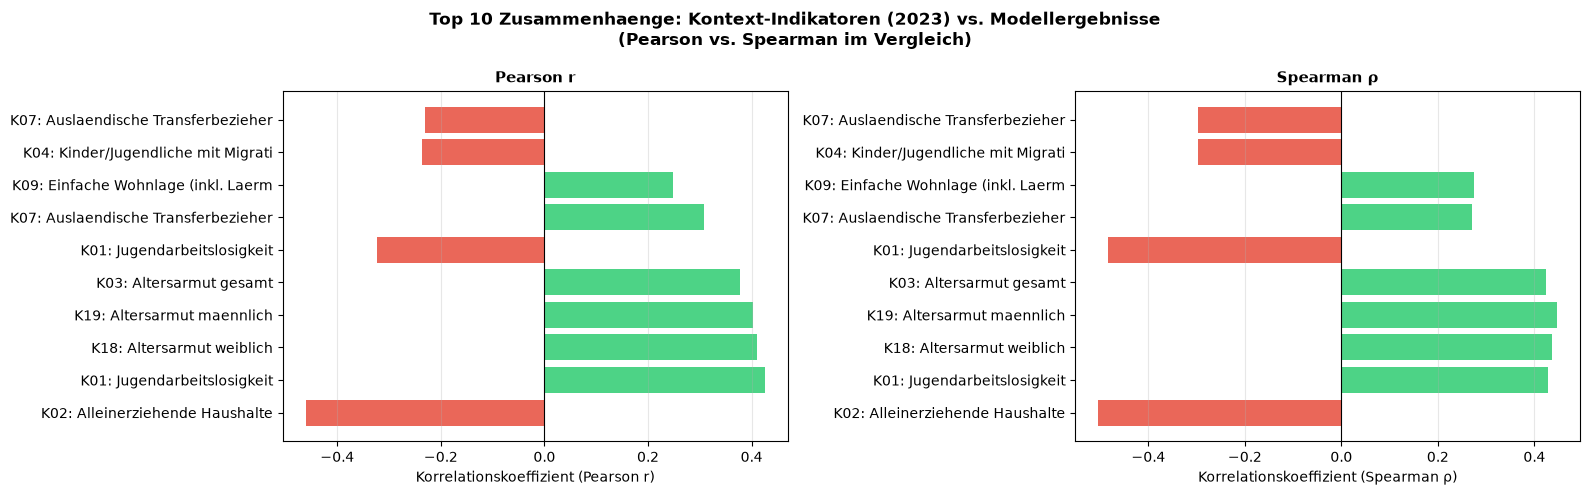

✅ Korrelations-Balkendiagramm (Pearson + Spearman) gespeichert!


In [6]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 6: Visualisierung der staerksten Zusammenhaenge
# ═══════════════════════════════════════════════════════════════

top_n = min(10, len(korr_df))
top_korr = korr_df.head(top_n).copy()
top_korr['Label'] = top_korr['Kontext_Indikator'] + ' (' + top_korr['Zielgroesse'].str[:20] + '...)'

fig, axes = plt.subplots(1, 2, figsize=(16, max(4, top_n * 0.5)))

for ax, spalte, titel in [
    (axes[0], 'Pearson_r', 'Pearson r'),
    (axes[1], 'Spearman_rho', 'Spearman ρ'),
]:
    colors = ['#2ecc71' if r > 0 else '#e74c3c' for r in top_korr[spalte]]
    ax.barh(range(len(top_korr)), top_korr[spalte], color=colors, alpha=0.85)
    ax.set_yticks(range(len(top_korr)))
    ax.set_yticklabels(top_korr['Kontext_Indikator'] + ': ' + top_korr['Beschreibung'].str[:30])
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel(f'Korrelationskoeffizient ({titel})')
    ax.set_title(titel, fontsize=11, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

plt.suptitle(f'Top {top_n} Zusammenhaenge: Kontext-Indikatoren (2023) vs. Modellergebnisse\n'
             f'(Pearson vs. Spearman im Vergleich)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/08_kontext_korrelationen.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Korrelations-Balkendiagramm (Pearson + Spearman) gespeichert!')

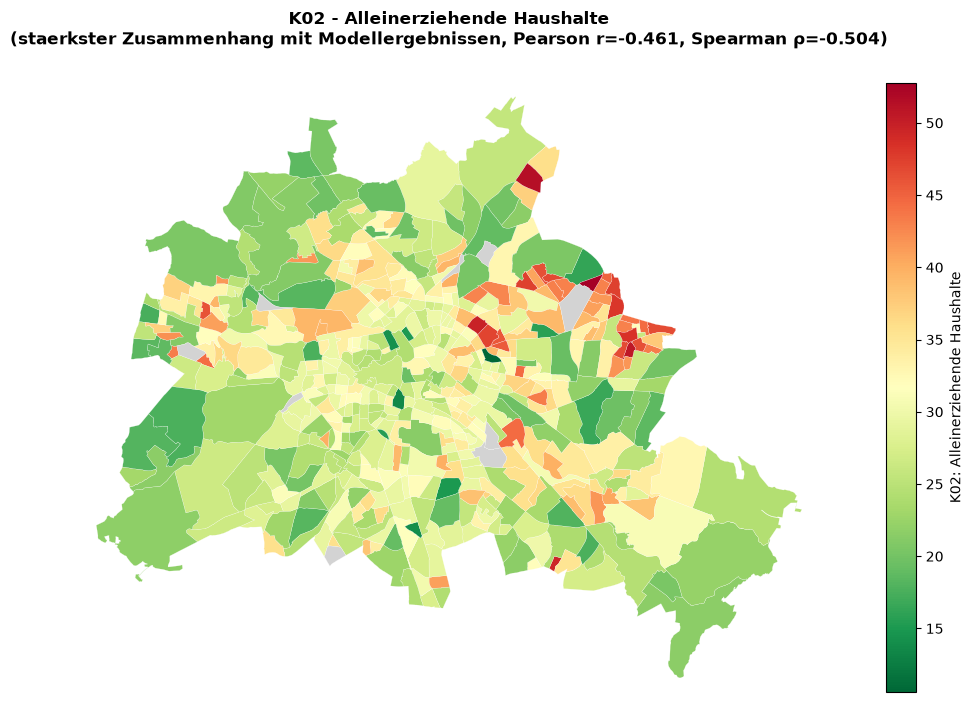

✅ Karte fuer staerksten Zusammenhang (K02) gespeichert!


In [7]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 7: Karte des staerksten Kontext-Zusammenhangs
# ═══════════════════════════════════════════════════════════════

if len(korr_df) > 0:
    staerkster = korr_df.iloc[0]
    k_top = staerkster['Kontext_Indikator']

    gdf_polygone = gpd.read_file('../data/final/plr_polygone.gpkg')
    gdf_polygone['plr_id'] = gdf_polygone['plr_id'].astype(str).str.zfill(8)
    gdf_kontext_karte = gdf_polygone.merge(
        df_analyse[['plr_id', k_top]], on='plr_id', how='left'
    )

    fig, ax = plt.subplots(figsize=(10, 9))
    gdf_kontext_karte.plot(
        column=k_top, cmap='RdYlGn_r', legend=True,
        edgecolor='white', linewidth=0.15,
        missing_kwds={'color': 'lightgrey'}, ax=ax,
        legend_kwds={'label': f'{k_top}: {K_BESCHREIBUNGEN.get(k_top, "")}', 'shrink': 0.7}
    )
    ax.set_title(f'{k_top} - {K_BESCHREIBUNGEN.get(k_top, "")}\n'
                 f'(staerkster Zusammenhang mit Modellergebnissen, '
                 f'Pearson r={staerkster["Pearson_r"]}, '
                 f'Spearman ρ={staerkster["Spearman_rho"]})',
                 fontsize=12, fontweight='bold')
    ax.set_axis_off()
    plt.tight_layout()
    plt.savefig(f'../results/08_karte_{k_top}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'✅ Karte fuer staerksten Zusammenhang ({k_top}) gespeichert!')

In [8]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 8: Zusammenfassung fuer die Masterarbeit
# ═══════════════════════════════════════════════════════════════

print('='*60)
print('NOTEBOOK 08 - KONTEXT-INDIKATOREN-ANALYSE ABGESCHLOSSEN')
print('='*60)
print(f'\nAnalysierte Planungsraeume: {len(df_analyse)}')
print(f'Analysierte Kontext-Indikatoren: {len(k_spalten)}')

signifikante = korr_df[korr_df['signifikant_5pct_pearson']]
print(f'\nSignifikante Zusammenhaenge (Pearson, p<0,05): {len(signifikante)} von {len(korr_df)}')

if len(signifikante) > 0:
    print('\n📊 Signifikante Kontext-Indikatoren:')
    print(signifikante[['Kontext_Indikator','Beschreibung','Zielgroesse',
                        'Pearson_r','Spearman_rho','Pearson_p']].to_string(index=False))
else:
    print('\n⚠️ Keine statistisch signifikanten Zusammenhaenge gefunden.')
    print('   Das ist auch ein valides, berichtenswertes Ergebnis:')
    print('   Die vom Modell identifizierten Einflussfaktoren scheinen')
    print('   weitgehend unabhaengig von den geprueften Kontext-Indikatoren zu sein.')

print(f'\n📊 Pearson vs. Spearman - mittlere absolute Differenz: '
      f'{korr_df["Differenz_abs"].mean():.3f}')

print('\n📁 Gespeicherte Dateien:')
for f in sorted(os.listdir('../results/')):
    if '08_' in f or 'kontext' in f:
        print(f'   {f}')

print('\n💡 Formulierungshinweis fuer Kapitel 6.1/6.3:')
print('   Diese Analyse ergaenzt die Kernmodellierung um eine post-hoc')
print('   Einordnung anhand amtlicher Kontext-Indikatoren, OHNE diese')
print('   in das Modelltraining selbst zu integrieren (vgl. Kapitel 3.2.4).')
print('   Pearson- und Spearman-Koeffizienten wurden vergleichend berechnet,')
print('   um die Robustheit der Ergebnisse gegenueber Abweichungen von der')
print('   Normalverteilungsannahme sozialraeumlicher Daten zu pruefen.')

NOTEBOOK 08 - KONTEXT-INDIKATOREN-ANALYSE ABGESCHLOSSEN

Analysierte Planungsraeume: 539
Analysierte Kontext-Indikatoren: 19

Signifikante Zusammenhaenge (Pearson, p<0,05): 23 von 32

📊 Signifikante Kontext-Indikatoren:
Kontext_Indikator                                 Beschreibung                                         Zielgroesse  Pearson_r  Spearman_rho  Pearson_p
              K02                   Alleinerziehende Haushalte              Staerke des dominanten SHAP-Einflusses     -0.461        -0.504     0.0000
              K01                       Jugendarbeitslosigkeit Prognostizierte Statusveraenderung 2025->2027 (TFT)      0.425         0.428     0.0000
              K18                         Altersarmut weiblich Prognostizierte Statusveraenderung 2025->2027 (TFT)      0.411         0.437     0.0000
              K19                        Altersarmut maennlich Prognostizierte Statusveraenderung 2025->2027 (TFT)      0.402         0.447     0.0000
              K03        